In [1]:
from pathlib import Path                      # Object-oriented file and directory paths
import json                                   # Reads/writes JSON data
import subprocess                             # Runs the automated pytest suite
import sys                                    # Access Python interpreter and system

import matplotlib.pyplot as plt               # Plots and visualizations
import numpy as np                            # Numerical computing and array operations
import pandas as pd                           # Data manipulation and analysis
from scipy.stats import kendalltau            # Measures the agreement between the rankings produced by WSM and TOPSIS.

# Adding the repository root to Python's module-search path only when it is not already present. 
#This makes the local src.mcda package importable without installing the project as a package.
ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

#Importing functions:
from src.mcda import (
    minmax_normalize,                         # converts mixed-scale cost/benefit criteria to a common 0-1 scale
    one_way_sensitivity,                      # varies one criterion weight and proportionally rescales the others
    rank_scores,                              # converts scores into ranks, with the largest score ranked first
    sample_weights,                           # draws valid random weight combinations for robustness analysis
    summarize_ranks,                          # calculates win frequencies and average ranks across simulations
    topsis,                                   # ranks suppliers by distance from ideal and anti-ideal solutions
    validate_problem,                         # checks the data, criterion directions, and weights before analysis
    weighted_sum,                             # calculates Weighted Sum Model scores using a matrix-vector product
)

# Improving table readability by showing up to 20 columns and four decimal places.
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

# Applying a clean chart theme and define a reusable, color-blind-conscious project palette.
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "blue": "#2563EB",
    "green": "#059669",
    "orange": "#EA580C",
    "purple": "#7C3AED",
    "gray": "#64748B",
}

# A fixed random seed makes the random-weight simulation reproducible.
SEED = 2026

# Performing a check by returning a short string that gives visible confirmation that the setup cell finished.
"Environment ready"

'Environment ready'

# Choosing the Best Supplier with Mathematics: #
## Weighted scoring, TOPSIS, and sensitivity analysis in Python ##

**Course:** Math Concepts for Developers  
**Author:** Boyan Yotov  
**Data:** Fully fictional educational dataset - no real supplier information is used  
**Date:** November 2026

> **Main question:** How can normalization, weights, and distance from ideal solutions turn several conflicting supplier criteria into a transparent recommendation - and how stable is that recommendation when assumptions change?

## Notebook map ##

1. Problem formulation and learning goals
2. Fictional data and assumptions
3. Mathematical foundations
4. Weighted Sum Model (WSM)
5. TOPSIS comparison
6. Scenario and sensitivity experiments
7. Robustness checks and an outlier experiment
8. Verification, limitations, and conclusions

### What you should be able to explain after reading: ###

- Why criteria measured in euros, days, percentages, and scores cannot be added directly?
- How cost and benefit criteria require different normalization formulas?
- Why a weighted score is a dot product?
- How does TOPSIS compare each supplier with ideal and anti-ideal points?
- Why does the word *best* always depend on stated weights, data, and model assumptions?
- How sensitivity analysis separates a stable recommendation from a fragile one?


---

## Abstract ##

Supplier selection is a multi-criteria decision problem: a low price can be offset by slow delivery, while strong quality can coexist with higher risk or weaker sustainability. This project creates a transparent mathematical model for comparing six fictional suppliers across six criteria. Direction-aware min-max normalization first places every criterion on a common 0-to-1 scale. The Weighted Sum Model (WSM) then combines normalized performance with explicit criterion weights through matrix-vector multiplication. A second method, TOPSIS, evaluates closeness to an ideal supplier and distance from an anti-ideal supplier.

The baseline assumptions select **Borealis Industries** with a WSM score of approximately **0.724**, narrowly ahead of **Evergreen Manufacturing** at approximately **0.718**. TOPSIS produces the same complete ranking under baseline weights. This agreement does not make the result universally correct: scenario analysis changes the winner when quality and reliability receive more emphasis, and one-way sensitivity shows winner changes near price weights of 0.23 and 0.48. In 5,000 reproducible random-weight simulations concentrated around the baseline, Borealis wins 59.04% of WSM runs and Evergreen 40.78%; TOPSIS and WSM choose the same winner in 77.38% of runs.

The main conclusion is that mathematics can make supplier selection consistent, inspectable, and reproducible, but it cannot remove human judgment. A responsible recommendation must report the selected weights, method, assumptions, margins, and stability tests rather than only the top-ranked name.

---

# 1. Problem formulation #

## 1.1 The real-world problem ##

A buyer may need to compare offers that are strong in different ways. One supplier can be inexpensive but slow; another can be reliable but costly. There is no natural unit that allows us to add euros, days, percentages, and risk scores. A mathematical decision model therefore has to perform three translations:

1. **Business alternatives -> rows** in a decision matrix.
2. **Business criteria -> numerical columns** with explicit directions.
3. **Business preferences -> weights** whose sum is one.

The output is a ranking, not an automatic procurement decision. Commercial terms, legal checks, technical qualification, capacity, contractual risk, and stakeholder approval remain outside this simplified educational model.

## 1.2 Research questions ##

1. How does direction-aware normalization make heterogeneous criteria comparable?
2. Do WSM and TOPSIS agree under the baseline assumptions?
3. Which assumptions can change the winning supplier?
4. Is the result robust to many plausible weight combinations?
5. How can a model be communicated without hiding value judgments?

## 1.3 Hypothesis

The two methods are expected to agree on the strongest suppliers under baseline weights, but the winner is expected to change when price or quality/reliability receives substantially more weight. A small winning margin should be treated as evidence for more review, not false precision.


## 1.4 Scope, assumptions, and success criteria ##

### Included ###

- six fictional alternatives and six numerical criteria
- three cost criteria and three benefit criteria
- WSM and TOPSIS rankings
- scenario, one-way, random-weight, leave-one-criterion-out, and outlier experiments
- reusable Python functions with automated tests

### Deliberate simplifications ###

- The data are point estimates, not audited observations or contractual guarantees.
- Criteria are treated as independent, although real criteria can be correlated.
- WSM assumes that poor performance on one criterion may be compensated by strong performance on another.
- Baseline weights are illustrative and are not claimed to represent any company policy.
- No mandatory threshold is enforced. In a real process, minimum quality or compliance requirements should be applied before scoring.

### Success criteria ###

The project is successful if the notebook is reproducible, formulas match the code, all automated tests pass, the recommendation can be traced to explicit assumptions, and ranking instability is reported rather than concealed.


# 2. Data and decision assumptions #

The dataset is intentionally small enough to calculate by hand. Every value is synthetic. This avoids confidentiality concerns and keeps attention on the mathematics.

A **cost criterion** is better when smaller. A **benefit criterion** is better when larger. The risk score is an invented 1-to-5 assessment where 1 indicates lower risk and 5 indicates higher risk.

In [8]:
# Loading the decision-model configuration and fictional supplier dataset,
# then validating them before any calculations are performed.

# Reading the UTF-8 JSON text and converting it into a Python dictionary.
config_path = ROOT / "config" / "decision_problem.json"
config = json.loads(config_path.read_text(encoding="utf-8"))

# Extracting the ordered criterion list, cost/benefit directions, and baseline weights.
# Preserving criterion order is important for matrix calculations and consistent displays.
criteria = config["criteria"]
directions = config["directions"]
baseline_weights = config["baseline_weights"]

# Loading the CSV into a pandas DataFrame and using supplier names as row labels.
data_path = ROOT / "data" / "fictional_suppliers.csv"
suppliers = pd.read_csv(data_path).set_index("Supplier")

# A clear error if columns, numeric data, directions, or weights are invalid.
validate_problem(suppliers, criteria, directions, baseline_weights)

# Display the validated raw decision matrix.
suppliers

,Unit Price (EUR),Delivery Time (days),Quality Score (%),On-Time Delivery (%),Sustainability Score,Risk Score
Supplier,,,,,,
Atlas Components,94,12,92,94,68,3.0
Borealis Industries,101,8,96,98,85,1.5
Cedar Supply,89,15,88,90,76,3.8
Delta Partners,98,9,94,96,80,2.0
Evergreen Manufacturing,104,7,97,97,92,1.8
Falcon Solutions,92,11,91,93,70,2.7


## 2.1 Data dictionary and weight rationale ##

The baseline gives price and quality the greatest weight (0.25 each), followed by delivery time and on-time delivery (0.15 each). Sustainability and risk receive 0.10 each. These choices are assumptions to test, not facts discovered from the data.

In [9]:
# Creating a data dictionary that explains every decision criterion,
# including its measurement unit, optimization direction, weight, and business meaning.

# Mapping each criterion to the unit used in the source dataset.
units = {
    "Unit Price (EUR)": "EUR per unit",
    "Delivery Time (days)": "calendar days",
    "Quality Score (%)": "percent",
    "On-Time Delivery (%)": "percent",
    "Sustainability Score": "0-100 points",
    "Risk Score": "1-5 points",
}

# Including interpretations for each variable and whether lower or higher values are preferable.
meaning = {
    "Unit Price (EUR)": "Quoted unit price; lower is preferred",
    "Delivery Time (days)": "Expected lead time; lower is preferred",
    "Quality Score (%)": "Expected accepted units; higher is preferred",
    "On-Time Delivery (%)": "Historical-style reliability estimate; higher is preferred",
    "Sustainability Score": "Composite educational rating; higher is preferred",
    "Risk Score": "Composite educational risk estimate; lower is preferred",
}

# Converting the dictionaries to aligned Series objects. pandas aligns rows by criterion name,
# preventing accidental dependence on dictionary display order.
data_dictionary = pd.DataFrame({
    "Direction": pd.Series(directions),
    "Baseline weight": pd.Series(baseline_weights),
    "Unit": pd.Series(units),
    "Interpretation": pd.Series(meaning),
})

# Display the completed documentation table.
data_dictionary

,Direction,Baseline weight,Unit,Interpretation
Unit Price (EUR),cost,0.25,EUR per unit,Quoted unit price; lower is preferred
Delivery Time (days),cost,0.15,calendar days,Expected lead time; lower is preferred
Quality Score (%),benefit,0.25,percent,Expected accepted units; higher is preferred
On-Time Delivery (%),benefit,0.15,percent,Historical-style reliability estimate; higher ...
Sustainability Score,benefit,0.10,0-100 points,Composite educational rating; higher is preferred
Risk Score,cost,0.10,1-5 points,Composite educational risk estimate; lower is ...


## 2.2 Exploratory view of the raw values ##

The small multiples below deliberately keep the original units. The chart makes the conflicts visible: Evergreen is strongest on several benefit criteria but has the highest price; Cedar is cheapest but slower and weaker on quality and reliability.


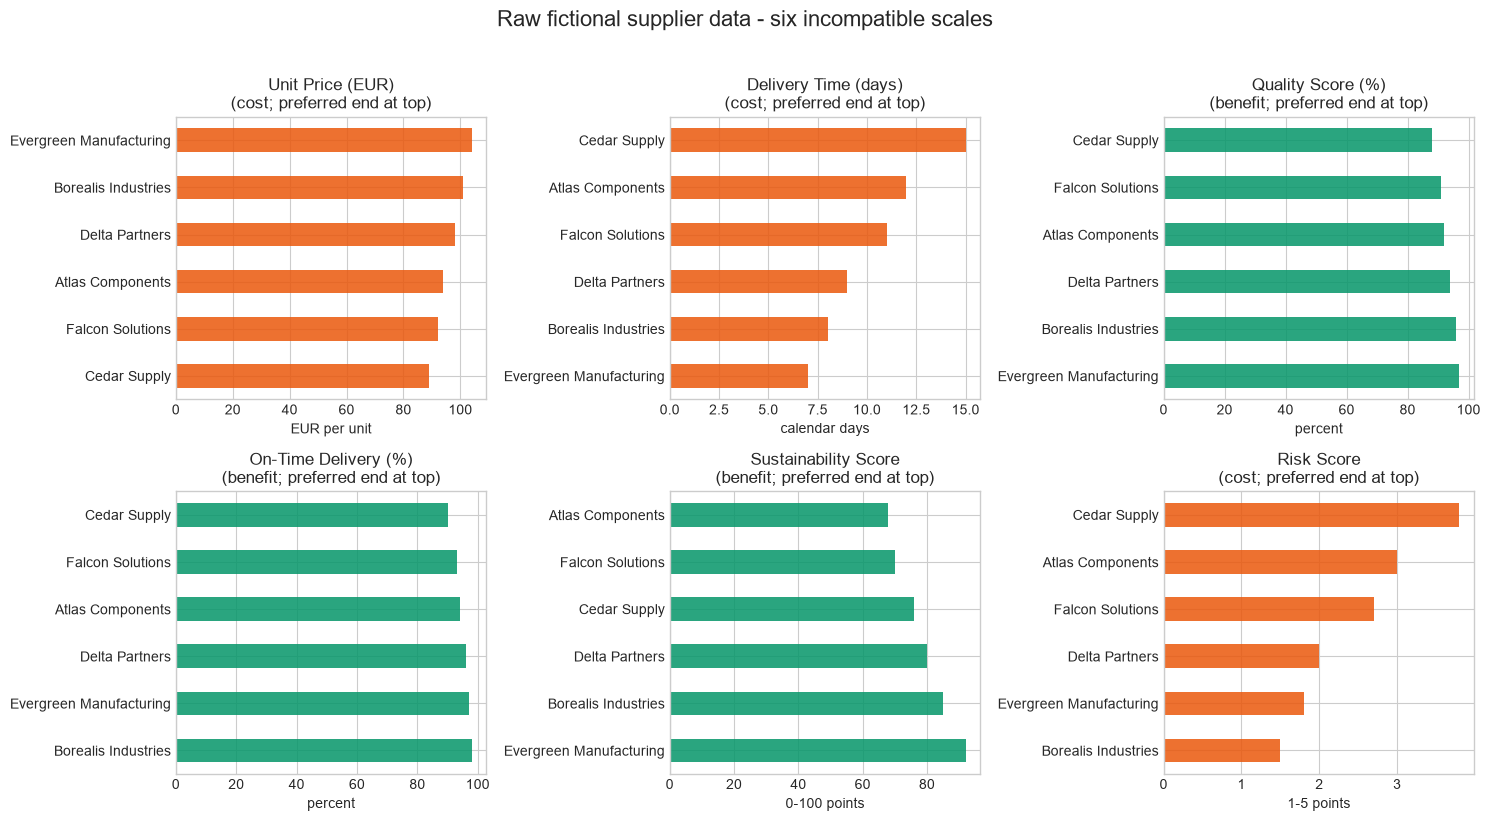

In [10]:
# Comparing all suppliers on the original measurement scales before normalization.
# A 2-by-3 grid provides one horizontal bar chart for each of the six criteria.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Pairing each subplot with one criterion. axes.flat turns the grid into a one-dimensional iterator.
for ax, criterion in zip(axes.flat, criteria):
    # Sort so the preferred values appear toward the top of each horizontal chart.
    # Cost criteria are sorted ascending; benefit criteria are sorted descending.
    ordered = suppliers[criterion].sort_values(ascending=directions[criterion] == "cost")

    # Using green for benefits and orange for costs to reinforce criterion direction visually.
    color = COLORS["green"] if directions[criterion] == "benefit" else COLORS["orange"]
    ordered.plot(kind="barh", ax=ax, color=color, alpha=0.85)

    # Adding titles, units, and clean axis labels.
    ax.set_title(f"{criterion}\n({directions[criterion]}; preferred end at top)")
    ax.set_xlabel(units[criterion])
    ax.set_ylabel("")

# Adding one shared title, resolve overlaps, and render the figure.
plt.suptitle("Raw fictional supplier data - six incompatible scales", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 2.3 Why a raw sum is invalid ##

Adding the raw columns would mix dimensions: one euro plus one day plus one percentage point has no meaningful interpretation. Large-number columns would dominate merely because of their units. The following intentionally incorrect calculation illustrates the problem; it is not used for any recommendation.


In [11]:
# Demonstration of why adding raw criterion values is mathematically invalid.
# The columns use incompatible units and ranges, so large-scale variables would dominate
# merely because of their measurement scale rather than their decision importance.

naive_raw_sum = (
    suppliers[criteria]
    .sum(axis=1)                 # Add across criteria for each supplier (axis=1 means rows).
    .sort_values(ascending=False)
    .rename("Invalid raw sum")
)

# Converting the Series to a one-column table for a clearer display.
naive_raw_sum.to_frame()

,Invalid raw sum
Supplier,
Evergreen Manufacturing,398.8
Borealis Industries,389.5
Delta Partners,379.0
Atlas Components,363.0
Cedar Supply,361.8
Falcon Solutions,359.7


# 3. Mathematical foundations #

## 3.1 Decision matrix ##

With $m$ suppliers and $n$ criteria, the raw decision matrix is

$$
X = [x_{ij}] \in \mathbb{R}^{m \times n},
$$

where $x_{ij}$ is supplier $i$'s observed value for criterion $j$. Here, $m=6$ and $n=6$.

## 3.2 Direction-aware min-max normalization ##

For a **benefit** criterion, where larger is preferred:

$$
r_{ij}=\frac{x_{ij}-\min_i(x_{ij})}{\max_i(x_{ij})-\min_i(x_{ij})}.
$$

For a **cost** criterion, where smaller is preferred:

$$
r_{ij}=\frac{\max_i(x_{ij})-x_{ij}}{\max_i(x_{ij})-\min_i(x_{ij})}.
$$

After this transformation, $0 \le r_{ij} \le 1$ and larger is always better. If every supplier has the same value, the denominator is zero. The implementation assigns 1 to everyone because the criterion provides no information for distinguishing alternatives.

### Important interpretation ##

Min-max normalization is relative to the alternatives in the dataset. Adding a new extreme supplier can change everybody's normalized values even when the original raw values have not changed. Section 8 tests this limitation explicitly.


In [12]:
# Transforming all criteria to a comparable 0-1 scale on which larger is always better.
normalized = minmax_normalize(suppliers, criteria, directions)

# Display a presentation-friendly copy rounded to four decimals.
normalized.round(4)

,Unit Price (EUR),Delivery Time (days),Quality Score (%),On-Time Delivery (%),Sustainability Score,Risk Score
Supplier,,,,,,
Atlas Components,0.6667,0.375,0.4444,0.500,0.0000,0.3478
Borealis Industries,0.2000,0.875,0.8889,1.000,0.7083,1.0000
Cedar Supply,1.0000,0.000,0.0000,0.000,0.3333,0.0000
Delta Partners,0.4000,0.750,0.6667,0.750,0.5000,0.7826
Evergreen Manufacturing,0.0000,1.000,1.0000,0.875,1.0000,0.8696
Falcon Solutions,0.8000,0.500,0.3333,0.375,0.0833,0.4783


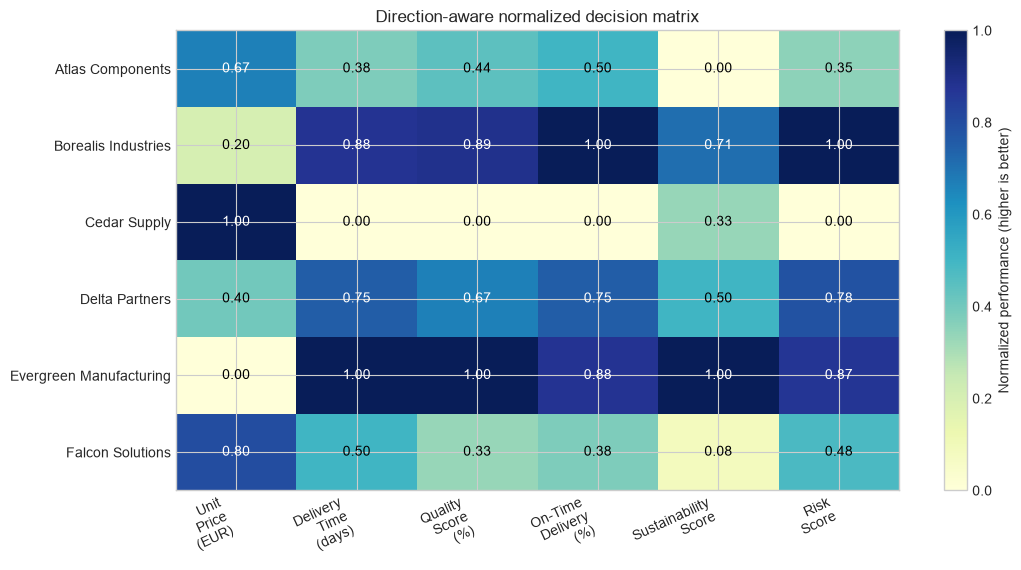

In [13]:
# Visualizing the normalized decision matrix as an annotated heat map.
fig, ax = plt.subplots(figsize=(11, 5.8))

# Converting the labeled DataFrame to a NumPy matrix for imshow. Fixed limits of 0 and 1
# preserve the mathematical meaning of the colors across the entire figure.
image = ax.imshow(
    normalized.to_numpy(),
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    aspect="auto",
)

# Using criterion names as column labels and supplier names as row labels.
ax.set_xticks(
    range(len(criteria)),
    [criterion.replace(" ", "\n") for criterion in criteria],
    rotation=25,
    ha="right",
)
ax.set_yticks(range(len(normalized)), normalized.index)

# Writing the exact normalized value in every heat-map cell.
for row_number in range(len(normalized)):
    for column_number in range(len(criteria)):
        value = normalized.iloc[row_number, column_number]
        text_color = "white" if value > 0.62 else "black"
        ax.text(
            column_number,
            row_number,
            f"{value:.2f}",
            ha="center",
            va="center",
            color=text_color,
        )

# Adding a scale legend and title, then render the completed chart.
fig.colorbar(image, ax=ax, label="Normalized performance (higher is better)")
ax.set_title("Direction-aware normalized decision matrix")
plt.tight_layout()
plt.show()

## 3.3 Weights as a preference vector ##

Let the weight vector be

$$
\mathbf{w}=(w_1,w_2,\ldots,w_n)^T,
\qquad w_j\ge 0,
\qquad \sum_{j=1}^{n}w_j=1.
$$

The constraints make the weights interpretable as shares of total importance. They do **not** come from normalization; they encode decision-maker preferences and should be agreed by stakeholders.

## 3.4 Weighted Sum Model as a dot product ##

For supplier $i$, WSM calculates

$$
S_i=\sum_{j=1}^{n} w_j r_{ij}
    = \mathbf{r}_i \cdot \mathbf{w}.
$$

For all suppliers at once:

$$
\mathbf{S}=R\mathbf{w}.
$$

Because every $r_{ij}$ is between 0 and 1 and the non-negative weights sum to 1, every $S_i$ is also between 0 and 1. The score is a weighted average, not a probability.

In [14]:
# Calculating the baseline Weighted Sum Model (WSM), rank suppliers,
# and verify the winner's score through a criterion-by-criterion decomposition.

# weighted_sum multiplies each normalized criterion by its weight and sums across columns.
wsm_scores = weighted_sum(normalized, baseline_weights)

# rank_scores assigns rank 1 to the highest WSM score.
wsm_ranks = rank_scores(wsm_scores)

# Identify the supplier with the maximum score.
baseline_winner = wsm_scores.idxmax()

# Building a table containing the winner's normalized performance and weights.
manual_check = pd.DataFrame({
    "Normalized value": normalized.loc[baseline_winner],
    "Weight": pd.Series(baseline_weights),
})

# Each contribution equals normalized performance multiplied by decision importance.
manual_check["Contribution"] = (
    manual_check["Normalized value"] * manual_check["Weight"]
)

# Adding totals: weights should equal 1, and contributions should reproduce the WSM score.
manual_check.loc["TOTAL"] = [
    np.nan,
    manual_check["Weight"].sum(),
    manual_check["Contribution"].sum(),
]

# Display the score decomposition for independent inspection.
manual_check

,Normalized value,Weight,Contribution
Unit Price (EUR),0.2000,0.25,0.0500
Delivery Time (days),0.8750,0.15,0.1313
Quality Score (%),0.8889,0.25,0.2222
On-Time Delivery (%),1.0000,0.15,0.1500
Sustainability Score,0.7083,0.10,0.0708
Risk Score,1.0000,0.10,0.1000
TOTAL,NaN,1.00,0.7243


The contribution column answers *why* the supplier obtained its score. The sum of contributions equals the matrix calculation. This audit trail is one advantage of WSM.

## 3.5 TOPSIS: distance from ideal and anti-ideal ##

WSM asks, “What is the weighted average performance?” TOPSIS asks, “Which alternative is closest to the ideal point and farthest from the worst point?”

The implementation follows five steps:

1. **Vector-normalize** each criterion:
   $$v_{ij}=w_j\frac{x_{ij}}{\sqrt{\sum_i x_{ij}^2}}.$$
2. Construct ideal $A^+$ and anti-ideal $A^-$ values according to cost/benefit direction.
3. Calculate Euclidean distance to the ideal:
   $$D_i^+=\sqrt{\sum_j(v_{ij}-A_j^+)^2}.$$
4. Calculate distance to the anti-ideal:
   $$D_i^-=\sqrt{\sum_j(v_{ij}-A_j^-)^2}.$$
5. Calculate closeness:
   $$C_i=\frac{D_i^-}{D_i^+ + D_i^-},\qquad 0\le C_i\le1.$$

A larger $C_i$ is preferred. TOPSIS adds geometric information, but it still depends on data, directions, weights, normalization, and the choice of Euclidean distance.

# 4. Baseline results #

A report presents scores, ranks, and margins. The ranking is ordinal; a score difference of 0.006 does not prove that one supplier is objectively better in every practical sense.

In [15]:
# Applying TOPSIS as a second MCDA method and comparing its baseline ranking with WSM.

# TOPSIS evaluates each supplier's weighted distance from ideal and anti-ideal solutions.
topsis_result = topsis(suppliers, criteria, directions, baseline_weights)

# Closeness is the final TOPSIS score; values nearer 1 indicate a more desirable alternative.
topsis_scores = topsis_result["TOPSIS Closeness"]
topsis_ranks = rank_scores(topsis_scores)

# Combining both methods into one supplier-indexed comparison table.
baseline_results = pd.DataFrame({
    "WSM Score": wsm_scores,
    "WSM Rank": wsm_ranks,
    "TOPSIS Closeness": topsis_scores,
    "TOPSIS Rank": topsis_ranks,
})

# Sorting primarily by WSM rank and secondarily by TOPSIS rank.
baseline_results = baseline_results.sort_values(["WSM Rank", "TOPSIS Rank"])
baseline_results

,WSM Score,WSM Rank,TOPSIS Closeness,TOPSIS Rank
Supplier,,,,
Borealis Industries,0.7243,1,0.7946,1
Evergreen Manufacturing,0.7182,2,0.7780,2
Delta Partners,0.6199,3,0.7158,3
Falcon Solutions,0.4707,4,0.4912,4
Atlas Components,0.4438,5,0.3784,5
Cedar Supply,0.2833,6,0.2143,6


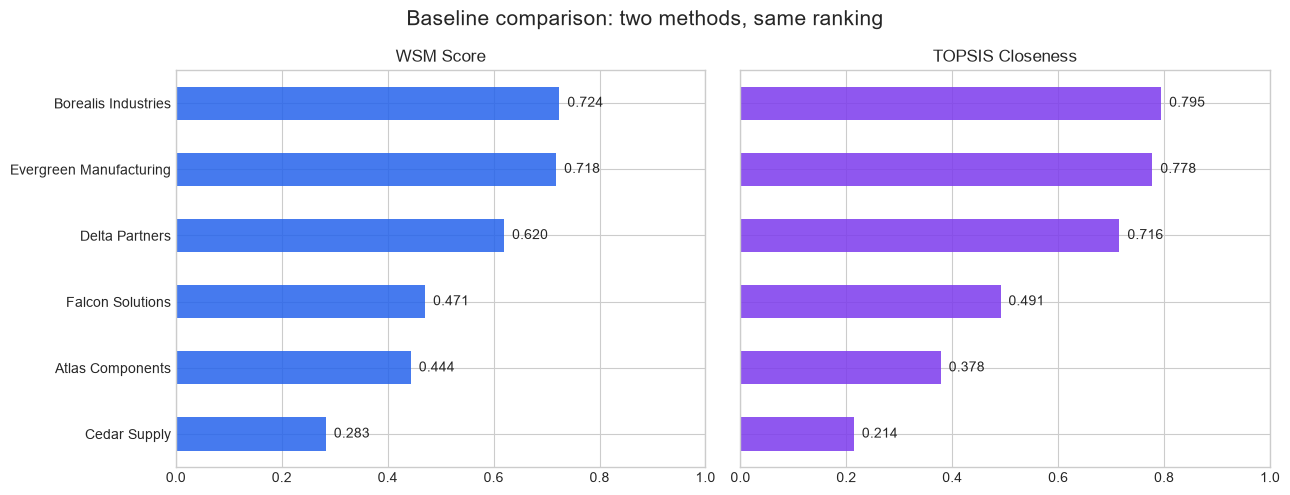

In [16]:
# Showing the baseline WSM and TOPSIS scores side by side on the same 0-1 scale.
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Each tuple supplies a subplot, score column, and method-specific color.
for ax, column, color in [
    (axes[0], "WSM Score", COLORS["blue"]),
    (axes[1], "TOPSIS Closeness", COLORS["purple"]),
]:
    # Ascending order places the strongest supplier at the top of a horizontal bar chart.
    ordered = baseline_results[column].sort_values()
    ordered.plot(kind="barh", ax=ax, color=color, alpha=0.85)

    # Using identical limits to make the visual comparison fair.
    ax.set_title(column)
    ax.set_xlim(0, 1)
    ax.set_ylabel("")

    # Labeling bars with their three-decimal score.
    for y_position, value in enumerate(ordered):
        ax.text(value + 0.015, y_position, f"{value:.3f}", va="center")

# Adding a shared heading, improve spacing, and render the figure.
plt.suptitle("Baseline comparison: two methods, same ranking", fontsize=15)
plt.tight_layout()
plt.show()

In [17]:
# Summarizing baseline agreement, decisiveness, and ranking similarity.

# Kendall's tau ranges from -1 (opposite order) to +1 (identical order).
# The p-value is reported for completeness but should be interpreted cautiously with six suppliers.
rank_tau, rank_p = kendalltau(wsm_ranks, topsis_ranks)

# The first-second margin measures how decisively the WSM winner leads the runner-up.
top_two_wsm_scores = wsm_scores.nlargest(2)
margin = top_two_wsm_scores.iloc[0] - top_two_wsm_scores.iloc[1]

# Assembling the key diagnostics into a labeled Series.
pd.Series({
    "WSM winner": wsm_scores.idxmax(),
    "TOPSIS winner": topsis_scores.idxmax(),
    "WSM first-second margin": margin,
    "Kendall rank correlation": rank_tau,
    "Kendall p-value (small sample)": rank_p,
}, name="Baseline diagnostic")

WSM winner                        Borealis Industries
TOPSIS winner                     Borealis Industries
WSM first-second margin                        0.0061
Kendall rank correlation                          1.0
Kendall p-value (small sample)                 0.0028
Name: Baseline diagnostic, dtype: object

## 4.1 Interpretation ##

Both methods rank Borealis first, Evergreen second, and Delta third. Kendall's $\tau=1$ means the full order is identical. However, the WSM gap between Borealis and Evergreen is only about 0.0061 on a 0-to-1 scale. Method agreement is useful evidence, but the small margin makes sensitivity analysis essential.

The calculation does **not** say Borealis is always best. It says Borealis is best *for these fictional observations, directions, weights, normalization rules, and compensatory assumptions*.


# 5. Scenario analysis #

Four scenarios are tested:

- **Baseline:** equal emphasis on price and quality, with moderate delivery and reliability importance.
- **Cost focused:** price and delivery jointly receive 60%.
- **Quality and reliability:** quality and on-time delivery jointly receive 55%.
- **Balanced:** all six criteria have equal weight.


In [18]:
# Defining alternative scenarios for testing how weight choices affect supplier scores and recommendations.

# Every inner dictionary assigns one non-negative weight to each criterion and sums to 1.
scenarios = {
    "Baseline": baseline_weights,
    "Cost focused": {
        "Unit Price (EUR)": 0.40,
        "Delivery Time (days)": 0.20,
        "Quality Score (%)": 0.15,
        "On-Time Delivery (%)": 0.10,
        "Sustainability Score": 0.05,
        "Risk Score": 0.10,
    },
    "Quality and reliability": {
        "Unit Price (EUR)": 0.15,
        "Delivery Time (days)": 0.10,
        "Quality Score (%)": 0.30,
        "On-Time Delivery (%)": 0.25,
        "Sustainability Score": 0.10,
        "Risk Score": 0.10,
    },
    # Equal weighting is generated dynamically so it remains valid if criteria are added or removed.
    "Balanced": {criterion: 1 / len(criteria) for criterion in criteria},
}

# Converting the nested dictionary to a table with scenarios as rows and criteria as columns.
scenario_weights = pd.DataFrame(scenarios).T
scenario_weights

,Unit Price (EUR),Delivery Time (days),Quality Score (%),On-Time Delivery (%),Sustainability Score,Risk Score
Baseline,0.2500,0.1500,0.2500,0.1500,0.1000,0.1000
Cost focused,0.4000,0.2000,0.1500,0.1000,0.0500,0.1000
Quality and reliability,0.1500,0.1000,0.3000,0.2500,0.1000,0.1000
Balanced,0.1667,0.1667,0.1667,0.1667,0.1667,0.1667


In [19]:
# Calculating WSM scores under every scenario and summarizing the recommendation, runner-up, and decision margin for each set of preferences.

# The dictionary comprehension returns one supplier-score Series per scenario;
# DataFrame construction aligns suppliers by name, and .T places scenarios on rows.
scenario_scores = pd.DataFrame({
    scenario_name: weighted_sum(normalized, weights)
    for scenario_name, weights in scenarios.items()
}).T

# Extracting the winner, winning score, second place, and first-second margin row by row.
scenario_winners = pd.DataFrame({
    "Winner": scenario_scores.idxmax(axis=1),
    "Winning score": scenario_scores.max(axis=1),
    "Second place": scenario_scores.apply(
        lambda row: row.nlargest(2).index[1], axis=1
    ),
    "Margin": scenario_scores.apply(
        lambda row: row.nlargest(2).iloc[0] - row.nlargest(2).iloc[1], axis=1
    ),
})

# Display the compact scenario comparison.
scenario_winners

,Winner,Winning score,Second place,Margin
Baseline,Borealis Industries,0.7243,Evergreen Manufacturing,0.0061
Cost focused,Borealis Industries,0.6237,Delta Partners,0.0355
Quality and reliability,Evergreen Manufacturing,0.8057,Borealis Industries,0.0007
Balanced,Evergreen Manufacturing,0.7908,Borealis Industries,0.0121


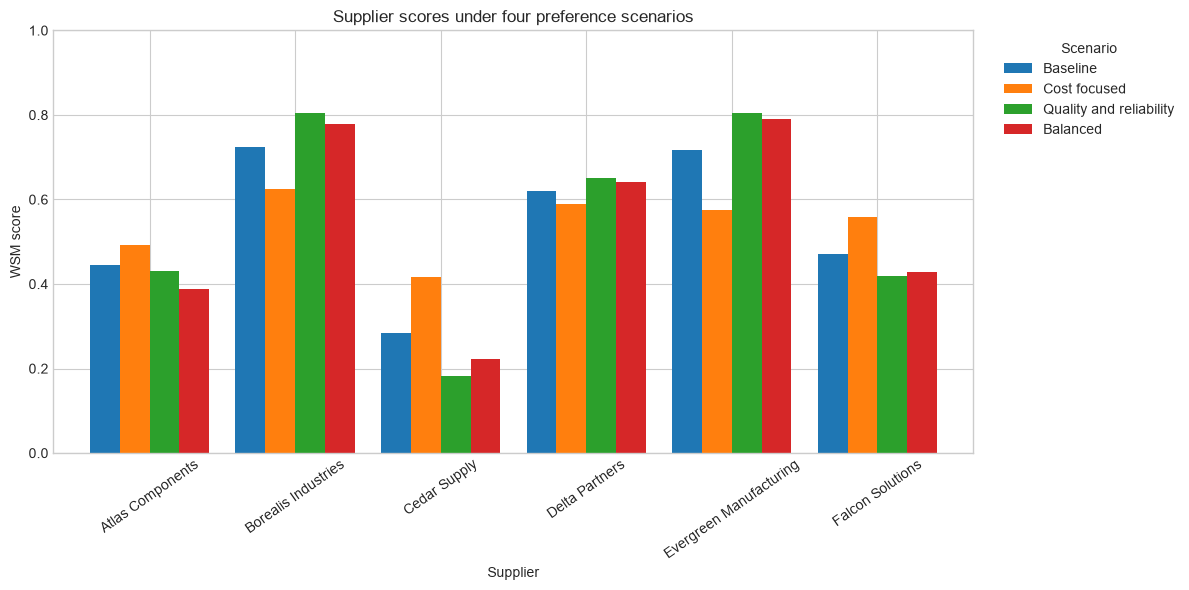

In [20]:
# Comparing all supplier WSM scores across the four preference scenarios.
fig, ax = plt.subplots(figsize=(12, 6))

# Transposing so suppliers become grouped x-axis categories and scenarios become colored series.
scenario_scores.T.plot(kind="bar", ax=ax, width=0.82)

# Scores are bounded by 0 and 1, so a fixed y-axis supports honest visual comparison.
ax.set_ylim(0, 1)
ax.set_ylabel("WSM score")
ax.set_title("Supplier scores under four preference scenarios")

# Placing the legend outside the plot and rotating long supplier labels for readability.
ax.legend(title="Scenario", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=35)

# Resolve overlaps and render the chart.
plt.tight_layout()
plt.show()

The baseline and cost-focused scenarios select Borealis, while the quality/reliability and equal-weight scenarios select Evergreen. 
This is not a defect: the model is correctly showing that different priorities can imply different recommendations. 
The practical task is to make those priorities explicit before comparing offers.

# 6. One-way sensitivity analysis #